# Chapter 13 : Processing Sequences Using RNNs and CNNs

In [3]:
import math
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn.functional as F
import torchmetrics
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, Dataset


/Users/voisin/Code/HOMLwithPytorch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'mps'

**-------------------------** 

**Exercice 1 : Use the Seq2SeqModel to forecast both rail and bus ridership for the next 14 days.**

**-------------------------** 

In [5]:
def download_and_extract_ridership_data():
    data_dir = Path("datasets")
    csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
    if csv_path.is_file():  # on teste le CSV, pas l'archive
        return csv_path
    data_dir.mkdir(parents=True, exist_ok=True)
    tarball_path = data_dir / "ridership.tgz"
    url = "https://github.com/ageron/data/raw/main/ridership.tgz"
    urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as tar:
        tar.extractall(path=data_dir, filter="data")
    return csv_path


path = download_and_extract_ridership_data()

df = pd.read_csv(path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date").drop(columns="total")
df = df[~df.index.duplicated(keep="first")]  # une seule ligne par date
df = df.asfreq("D")  # index quotidien, aucune ligne ajoutée ici

print(df.shape, df.index.min().date(), df.index.max().date())

(7639, 3) 2001-01-01 2021-11-30


In [ ]:
# Fonction d'entrainement
def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    patience=10,
    factor=0.1,
    max_grad_norm=1.0,
    trial=None,
    verbose=True,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor
    )
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": [], "lrs": []}
    best_metric, best_state = float("inf"), None

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            if not math.isfinite(loss.item()):  # divergence
                if trial is not None:
                    raise optuna.TrialPruned()
                raise RuntimeError(
                    f"Perte non finie à l'epoch {epoch + 1} : learning rate trop élevé ?"
                )
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred[:, -1].contiguous(), y_batch[:, -1].contiguous())

        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        if val_metric < best_metric:  # meilleur epoch
            best_metric = val_metric
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        scheduler.step(val_metric)

        if trial is not None:  # pruning Optuna
            trial.report(val_metric, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if verbose:
            print(
                f"Epoch {epoch + 1}/{n_epochs}, "
                f"train loss: {history['train_losses'][-1]:.4f}, "
                f"train metric: {history['train_metrics'][-1]:.4f}, "
                f"valid metric: {val_metric:.4f}"
            )

    model.load_state_dict(best_state)  # le modèle final = le meilleur epoch
    return history

In [ ]:
# Fonction d'évaluation


def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()


def evaluate_per_variable(
    model, data_loader, names=("bus", "rail"), scale=1e6, last_step_only=True
):
    model.eval()
    abs_err, n = None, 0
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            pred = model(X)  # (B, L, 2, T)
            assert pred.shape == y.shape, (
                f"pred {tuple(pred.shape)} != y {tuple(y.shape)}"
            )
            assert y.shape[-2] == len(names), (
                f"{y.shape[-2]} variable(s) dans les cibles, {len(names)} noms donnés"
            )
            if last_step_only:
                pred, y = pred[:, -1], y[:, -1]  # (B, 2, T)
            err = (pred - y).abs().movedim(-2, 0).reshape(len(names), -1)  # (2, B*T)
            abs_err = err.sum(dim=1) if abs_err is None else abs_err + err.sum(dim=1)
            n += err.shape[1]
    mae = abs_err / n * scale
    return {name: mae[i].item() for i, name in enumerate(names)}


def fit_and_evaluate(
    model,
    train_loader,
    valid_loader,
    lr,
    weight_decay=0.01,
    n_epochs=50,
    patience=20,
    factor=0.1,
):
    loss_fn = nn.HuberLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)
    history = train(
        model,
        optimizer,
        loss_fn,
        metric,
        train_loader,
        valid_loader,
        n_epochs=n_epochs,
        patience=patience,
        factor=factor,
    )
    return min(history["valid_metrics"]) * 1e6

In [ ]:
# Classe personnalisée pour les datasets
class Seq2SeqDataset(Dataset):
    def __init__(self, series, window_length, window_target):
        self.series = series
        self.window_length = window_length
        self.window_target = window_target

    def __len__(self):
        return len(self.series) - self.window_length - self.window_target + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx:end]
        target_period = self.series[idx + 1 : end + self.window_target, :2]
        target = target_period.unfold(dimension=0, size=self.window_target, step=1)
        return window, target

In [42]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

In [43]:
mulvar_train = torch.FloatTensor(df_mulvar["2016-01":"2018-12"].values)
mulvar_valid = torch.FloatTensor(df_mulvar["2019-01":"2019-05"].values)
mulvar_test = torch.FloatTensor(df_mulvar["2019-06":].values)

In [ ]:
# Création des datasets et dataloaders
window_length = 56
window_target = 14
seq_train_set = Seq2SeqDataset(mulvar_train, window_length, window_target)
seq_train_loader = DataLoader(seq_train_set, batch_size=32, shuffle=True)
seq_valid_set = Seq2SeqDataset(mulvar_valid, window_length, window_target)
seq_valid_loader = DataLoader(seq_valid_set, batch_size=32)
seq_test_set = Seq2SeqDataset(mulvar_test, window_length, window_target)
seq_test_loader = DataLoader(seq_test_set, batch_size=32)

In [ ]:
class Seq2SeqRnnModel(nn.Module):
    def __init__(
        self,
        input_size,
        window_target,
        hidden_size=32,
        n_layers=2,
        rnn_type="rnn",
        dropout=0.0,
    ):
        super().__init__()
        rnn_class = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[rnn_type]
        self.window_target = window_target
        self.rnn = rnn_class(
            input_size,
            hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.output = nn.Linear(hidden_size, window_target * 2)  # 2 variables prédites

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.output(out)
        return out.unflatten(-1, (2, self.window_target))

In [ ]:
SCALE = 1e6  # seulement si la série a été divisée par 1e6 (sinon voir plus bas)
N_EPOCHS_SEARCH = 20  # fixe pour tous les essais


def build_model(rnn_type, hidden_size, n_layers, dropout):
    torch.manual_seed(42)  # mêmes poids de départ pour des essais comparables
    n_features = seq_train_loader.dataset.series.shape[1]
    return Seq2SeqRnnModel(
        input_size=n_features,
        window_target=window_target,
        hidden_size=hidden_size,
        n_layers=n_layers,
        rnn_type=rnn_type,
        dropout=dropout,
    ).to(device)


def objective(trial):
    params = {
        "rnn_type": trial.suggest_categorical("rnn_type", ["rnn", "gru", "lstm"]),
        "hidden_size": trial.suggest_int("hidden_size", 16, 128, step=16),
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "dropout": trial.suggest_float(
            "dropout", 0.0, 0.3, step=0.1
        ),  # ignoré si n_layers == 1
    }
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-1, log=True)

    model = build_model(**params)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)

    history = train(
        model,
        optimizer,
        nn.HuberLoss(),
        metric,
        seq_train_loader,
        seq_valid_loader,
        n_epochs=N_EPOCHS_SEARCH,
        patience=5,
        factor=0.5,
        trial=trial,
        verbose=False,
    )
    return min(history["valid_metrics"]) * SCALE  # MAE de validation, en passagers

In [ ]:
Path("models/ch13").mkdir(parents=True, exist_ok=True)

sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)

study = optuna.create_study(
    study_name="seq2seq_rnn_v3",
    direction="minimize",  # on minimise une erreur
    sampler=sampler,
    pruner=pruner,
    storage="sqlite:///models/ch13/optuna.db",  # sauvegarde sur disque
    load_if_exists=True,  # permet de reprendre
)
study.optimize(objective, n_trials=30, gc_after_trial=True)

print("Meilleure MAE de validation :", study.best_value)
print("Meilleurs paramètres :", study.best_params)

[I 2026-11-14 19:40:06,153] A new study created in RDB with name: seq2seq_rnn_v3
[I 2026-11-14 19:40:17,781] Trial 0 finished with value: 124212.3395204544 and parameters: {'rnn_type': 'gru', 'hidden_size': 80, 'n_layers': 1, 'dropout': 0.0, 'lr': 0.00013066739238053285, 'weight_decay': 0.021423021757741075}. Best is trial 0 with value: 124212.3395204544.
[I 2026-11-14 19:40:53,530] Trial 1 finished with value: 38903.314620256424 and parameters: {'rnn_type': 'gru', 'hidden_size': 128, 'n_layers': 3, 'dropout': 0.0, 'lr': 0.0002310201887845295, 'weight_decay': 8.260808399079606e-06}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:17,436] Trial 2 finished with value: 62170.155346393585 and parameters: {'rnn_type': 'gru', 'hidden_size': 48, 'n_layers': 2, 'dropout': 0.0, 'lr': 0.0003839629299804173, 'weight_decay': 6.789053271698483e-05}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:41,909] Trial 3 finished with value: 35713.52735161781 and para

Meilleure MAE de validation : 31167.974695563316
Meilleurs paramètres : {'rnn_type': 'lstm', 'hidden_size': 80, 'n_layers': 2, 'dropout': 0.1, 'lr': 0.006343056874655127, 'weight_decay': 0.011348775788931446}


In [ ]:
torch.manual_seed(42)
seq_model = Seq2SeqRnnModel(
    input_size=5,
    window_target=window_target,
    n_layers=2,
    hidden_size=80,
    rnn_type="lstm",
    dropout=0.1,
)
seq_model = seq_model.to(device)
fit_and_evaluate(
    seq_model,
    seq_train_loader,
    seq_valid_loader,
    lr=6e-3,
    weight_decay=1e-2,
    n_epochs=65,
    patience=8,
    factor=0.5,
)

Epoch 1/65, train loss: 0.0410, train metric: 0.2247, valid metric: 0.1536
Epoch 2/65, train loss: 0.0181, train metric: 0.1649, valid metric: 0.1494
Epoch 3/65, train loss: 0.0113, train metric: 0.1220, valid metric: 0.0983
Epoch 4/65, train loss: 0.0059, train metric: 0.0776, valid metric: 0.0708
Epoch 5/65, train loss: 0.0046, train metric: 0.0643, valid metric: 0.0600
Epoch 6/65, train loss: 0.0045, train metric: 0.0618, valid metric: 0.0535
Epoch 7/65, train loss: 0.0043, train metric: 0.0600, valid metric: 0.0497
Epoch 8/65, train loss: 0.0041, train metric: 0.0592, valid metric: 0.0497
Epoch 9/65, train loss: 0.0040, train metric: 0.0575, valid metric: 0.0682
Epoch 10/65, train loss: 0.0041, train metric: 0.0594, valid metric: 0.0484
Epoch 11/65, train loss: 0.0039, train metric: 0.0573, valid metric: 0.0448
Epoch 12/65, train loss: 0.0038, train metric: 0.0552, valid metric: 0.0581
Epoch 13/65, train loss: 0.0038, train metric: 0.0558, valid metric: 0.0452
Epoch 14/65, train lo

44835.80216765404

In [54]:
print(evaluate_per_variable(seq_model, seq_valid_loader))

{'bus': 34376.8515625, 'rail': 33921.5859375}


In [ ]:
seq_model.eval()
with torch.no_grad():
    some_window = mulvar_valid[:window_length]  # shape [56, 5]
    X = some_window.unsqueeze(dim=0)  # shape [1, 56, 5]
    Y_preds = seq_model(X.to(device))  # shape [1, 56, 2, 14]
    Y_pred = Y_preds[0, -1]  # shape [2, 14]

<class 'numpy.ndarray'> (2, 14)


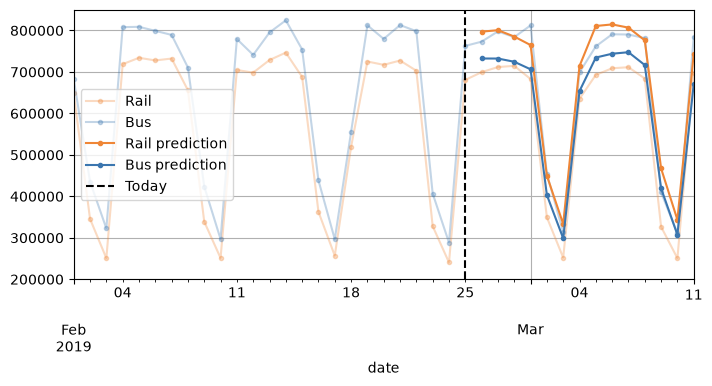

In [ ]:
# Y_pred : sortie du modèle au dernier pas, forme (2, 14) = (variable, jour)
Y_pred = Y_pred.detach().cpu().numpy()
print(type(Y_pred), Y_pred.shape)  # <class 'numpy.ndarray'> (2, 14)

today = pd.Timestamp("2019-02-25")  # dernier jour de la fenêtre d'entrée
future = pd.date_range(today + pd.Timedelta(days=1), periods=Y_pred.shape[1])

# L'ordre doit être celui des deux premières colonnes du tenseur d'entrée
Y_pred_bus_s = pd.Series(Y_pred[0] * 1e6, index=future)
Y_pred_rail_s = pd.Series(Y_pred[1] * 1e6, index=future)

recent = df[today - pd.Timedelta(days=24) : future[-1]]  # du 1er février au 11 mars

fig, ax = plt.subplots(figsize=(8, 3.5))
recent["rail"].plot(label="Rail", marker=".", ax=ax, color="#ef8636", alpha=0.3)
recent["bus"].plot(label="Bus", marker=".", ax=ax, color="#3b76af", alpha=0.3)
Y_pred_rail_s.plot(
    grid=True, marker=".", ax=ax, color="#ef8636", label="Rail prediction"
)
Y_pred_bus_s.plot(grid=True, marker=".", ax=ax, color="#3b76af", label="Bus prediction")
ax.axvline(today, color="k", linestyle="--", label="Today")
ax.set_ylim([200_000, 850_000])
ax.legend(loc="center left")
plt.show()

**-------------------------** 

**Exercice 2 : Train a model to predict the next note from a Bach chorales dataset. Then use this model to generate a Bach-like music.**

**-------------------------** 

In [5]:
from IPython.display import Audio

In [6]:
def download_and_extract_bach_data():
    """
    Télécharge et extrait le jeu de données JSB Chorales (chorals de Bach),
    puis renvoie les chemins des fichiers CSV pour chaque split.

    Le téléchargement n'a lieu que si les données ne sont pas déjà présentes
    (vérification de datasets/jsb_chorales/train/chorale_000.csv).

    Entrée
    ------
    Aucune, le lien de téléchargement est hardcodé dans la fonction.

    Sortie
    ------
    csv_list : dict[str, list[Path]]
        Dictionnaire avec les clés "train", "valid" et "test".
        Chaque valeur est la liste triée des chemins vers les fichiers
        chorale_*.csv du split :
            - "train" : 229 fichiers
            - "valid" : 76 fichiers
            - "test"  : 77 fichiers

    Contenu de chaque CSV
    ---------------------
    Un choral de N lignes x 4 colonnes (N varie d'un choral à l'autre).
        - Chaque ligne est un accord, c'est-à-dire un pas de temps.
        - Les 4 colonnes sont les 4 voix (note0 à note3).
        - Chaque valeur est un numéro de note MIDI entre 36 et 81,
          ou 0 pour un silence.
    """

    data_dir = Path("datasets")
    bach_dir = data_dir / "jsb_chorales"

    # On vérifie si le premier CSV existe déjà dans datasets/jsb_chorales/train/
    if not (bach_dir / "train" / "chorale_000.csv").is_file():
        data_dir.mkdir(parents=True, exist_ok=True)
        tarball_path = data_dir / "jsb_chorales.tgz"
        url = "https://homl.info/bach"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as tar:
            tar.extractall(path=data_dir, filter="data")

    csv_list = {
        split: sorted((bach_dir / split).glob("chorale_*.csv"))
        for split in ("train", "valid", "test")
    }
    return csv_list


bach_csv_list = download_and_extract_bach_data()

# Vérification :
for split, files in bach_csv_list.items():
    print(f"{split}: {len(files)} fichiers")

train: 229 fichiers
valid: 76 fichiers
test: 77 fichiers


In [7]:
def load_chorales(filepaths):
    """
    Charge une liste de fichiers CSV de chorals sous forme de tenseurs PyTorch.

    Entrée
    ------
    filepaths : list[Path]
        Chemins des fichiers chorale_*.csv d'un split,
        par exemple bach_datasets_list["train"].

    Sortie
    ------
    chorales : list[torch.Tensor]
        Un tenseur par fichier, dans le même ordre que filepaths.
        Chaque tenseur :
            - forme (N, 4), N étant le nombre de lignes du CSV,
              qui varie d'un choral à l'autre (par exemple 192, 196 ou 228)
            - type torch.long
            - valeurs brutes du CSV : 36 à 81 pour une note MIDI, 0 pour un silence
    """
    chorales = []
    for path in filepaths:
        df = pd.read_csv(path)  # tableau (N, 4)
        chorale = torch.tensor(df.values, dtype=torch.long)
        chorales.append(chorale)
    return chorales


bach_chorales = {split: load_chorales(files) for split, files in bach_csv_list.items()}

# Vérification :
for split, chorales in bach_chorales.items():
    print(
        f"{split}: {len(chorales)} chorals, premier de forme {tuple(chorales[0].shape)}"
    )

train: 229 chorals, premier de forme (192, 4)
valid: 76 chorals, premier de forme (196, 4)
test: 77 chorals, premier de forme (228, 4)


In [8]:
def play_chorale(chorale, chord_duration=0.25, sample_rate=44100):
    """
    Joue un choral dans le notebook.

    chorale : tenseur ou tableau (N, 4) de notes MIDI brutes (36 à 81, 0 = silence)
    chord_duration : durée d'un accord en secondes
    """
    notes = np.asarray(chorale)  # (N, 4)
    samples = int(sample_rate * chord_duration)  # échantillons par accord

    freqs = 440 * 2 ** ((notes - 69) / 12)  # note MIDI -> fréquence en Hz
    freqs = np.repeat(freqs, samples, axis=0)  # (N * samples, 4)
    is_note = np.repeat(notes != 0, samples, axis=0)  # False pendant les silences

    phase = 2 * np.pi * np.cumsum(freqs, axis=0) / sample_rate
    audio = (np.sin(phase) * is_note).sum(axis=1) / 4  # mélange des 4 voix
    return Audio(audio, rate=sample_rate)


play_chorale(bach_chorales["train"][0])

In [9]:
def make_features(notes, first_note_idx, total_chords, n_classes=47):
    """
    Construit les entrées du modèle pour une suite de notes d'un choral.

    Paramètres
    ----------
    notes : torch.Tensor, forme (T,), notes de 0 à 46.
    first_note_idx : int
        Position de la première note dans le choral entier (0 = première note du choral).
    total_chords : int
        Nombre total d'accords du choral, pour calculer l'avancement.
    n_classes : int, défaut 47

    Renvoie
    -------
    X : torch.Tensor, forme (T, 56), type float :
        - 47 : la note en one-hot
        - 4  : rang de la note dans l'accord (0 à 3) en one-hot
        - 4  : index de l'accord modulo 4 en one-hot
        - 1  : avancement dans le choral, de 0 (premier accord) à 1 (dernier)
    """
    T = len(notes)
    position = torch.arange(first_note_idx, first_note_idx + T, device=notes.device)

    voice = position % 4  # rang dans l'accord : 0, 1, 2, 3, 0, 1...
    chord_idx = position // 4  # numéro de l'accord dans le choral
    chord_mod4 = chord_idx % 4  # 0, 1, 2, 3, 0, 1...
    progress = chord_idx.float() / max(total_chords - 1, 1)

    return torch.cat(
        [
            F.one_hot(notes, num_classes=n_classes).float(),  # (T, 47)
            F.one_hot(voice, num_classes=4).float(),  # (T, 4)
            F.one_hot(chord_mod4, num_classes=4).float(),  # (T, 4)
            progress.unsqueeze(-1),  # (T, 1)
        ],
        dim=-1,
    )  # (T, 56)

In [10]:
class BachNotesDataset(Dataset):
    """
    Dataset qui met les accords bout à bout en une suite de notes,
    pour prédire la note suivante à chaque pas.

    Paramètres
    ----------
    chorales_list : list[torch.Tensor]
        Chorals bruts, chacun de forme (N, 4), par exemple bach_chorales["train"].
    window_length : int, défaut 32
        Nombre d'accords par fenêtre, soit window_length * 4 notes.
    shift : int, défaut 16
        Décalage, en accords, entre deux fenêtres successives d'un même choral.
    min_note : int, défaut 36
        Note MIDI la plus basse, utilisée pour convertir les notes en classes.

    __getitem__(idx) renvoie
    ------------------------
    X : torch.Tensor, forme (window_length * 4, 56), type float
        Entrées du modèle, construites par make_features.
    target : torch.Tensor, forme (window_length * 4,), type long
        Note suivante à chaque pas (0 à 46).
    """

    def __init__(self, chorales_list, window_length=32, shift=16, min_note=36):
        self.window_notes = window_length * 4
        self.chorales = []  # un tenseur 1D de notes par choral
        self.index = []  # (numéro du choral, position de départ en notes)

        for chorale_idx, chords in enumerate(chorales_list):
            # 0 = silence, sinon on ramène les notes 36..81 vers les classes 1..46
            chords = torch.where(chords == 0, chords, chords - min_note + 1)
            self.chorales.append(chords.flatten())  # (N, 4) -> (N * 4,)

            for start_chord in range(0, len(chords) - window_length, shift):
                self.index.append((chorale_idx, start_chord * 4))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        chorale_idx, start = self.index[idx]
        end = start + self.window_notes
        notes = self.chorales[chorale_idx]
        total_chords = len(notes) // 4

        X = make_features(notes[start:end], start, total_chords)  # (128, 56)
        target = notes[start + 1 : end + 1]  # (128,)
        return X, target

In [11]:
train_set = BachNotesDataset(bach_chorales["train"])
valid_set = BachNotesDataset(bach_chorales["valid"], shift=1)
test_set = BachNotesDataset(bach_chorales["test"], shift=1)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

In [12]:
class BachNoteRNN(nn.Module):
    """
    Modèle récurrent qui prédit la note suivante à chaque pas.

    Paramètres
    ----------
    n_features : int, défaut 56
        Taille du vecteur d'entrée par note (voir make_features).
    n_classes : int, défaut 47
    hidden_size : int, défaut 128
    num_layers : int, défaut 2
    dropout : float, défaut 0.2

    Entrée
    ------
    X : torch.Tensor, forme (batch, T, 56), type float.

    Sortie
    ------
    logits : torch.Tensor, forme (batch, 47, T)
        Scores des 47 classes pour la note suivante, à chaque pas.
    """

    def __init__(
        self, n_features=56, n_classes=47, hidden_size=128, num_layers=2, dropout=0.2
    ):
        super().__init__()
        self.gru = nn.GRU(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, n_classes)

    def forward(self, X):
        outputs, _ = self.gru(X)  # (batch, T, hidden_size)
        logits = self.head(self.dropout(outputs))  # (batch, T, 47)
        return logits.permute(0, 2, 1)  # (batch, 47, T)

In [14]:
def evaluate(model, loader, loss_fn, metric):
    """Renvoie (perte moyenne, métrique) sur toutes les notes du loader."""
    model.eval()
    metric.reset()
    total_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)  # (batch, 47, T)
            total_loss += loss_fn(y_pred, y_batch).item()
            metric.update(y_pred, y_batch)
    return total_loss / len(loader), metric.compute().item()


def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    mode="max",
    lr_patience=3,
    factor=0.1,
    early_stop_patience=8,
    max_grad_norm=1.0,
    trial=None,
    verbose=True,
):
    """
    Entraîne le modèle et le recharge avec les poids du meilleur epoch.
    Renvoie history : train_losses, valid_losses, train_metrics, valid_metrics, lrs.
    """
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode=mode, patience=lr_patience, factor=factor
    )
    history = {
        "train_losses": [],
        "valid_losses": [],
        "train_metrics": [],
        "valid_metrics": [],
        "lrs": [],
    }
    best_metric = float("-inf") if mode == "max" else float("inf")
    best_state = None
    epochs_without_progress = 0

    for epoch in range(n_epochs):
        # ----- Entraînement -----
        model.train()
        metric.reset()
        total_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss_value = loss.item()
            if not math.isfinite(loss_value):  # divergence
                if trial is not None:
                    raise optuna.TrialPruned()
                raise RuntimeError(
                    f"Perte non finie à l'epoch {epoch + 1} : learning rate trop élevé ?"
                )
            total_loss += loss_value
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred.detach(), y_batch)

        train_loss = total_loss / len(train_loader)
        train_metric = metric.compute().item()

        # ----- Validation -----
        valid_loss, valid_metric = evaluate(model, valid_loader, loss_fn, metric)

        history["train_losses"].append(train_loss)
        history["valid_losses"].append(valid_loss)
        history["train_metrics"].append(train_metric)
        history["valid_metrics"].append(valid_metric)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        if verbose:
            print(
                f"Epoch {epoch + 1}/{n_epochs} | "
                f"loss train {train_loss:.4f} valid {valid_loss:.4f} | "
                f"metric train {train_metric:.4f} valid {valid_metric:.4f} | "
                f"lr {history['lrs'][-1]:.1e}"
            )

        # ----- Pruning Optuna -----
        if trial is not None:
            trial.report(valid_metric, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        # ----- Meilleur epoch et arrêt anticipé -----
        if mode == "max":
            improved = valid_metric > best_metric
        else:
            improved = valid_metric < best_metric
        if improved:
            best_metric = valid_metric
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            epochs_without_progress = 0
        else:
            epochs_without_progress += 1
            if epochs_without_progress >= early_stop_patience:
                if verbose:
                    print(
                        f"Arrêt anticipé : pas de progrès depuis {early_stop_patience} epochs."
                    )
                break

        scheduler.step(valid_metric)

    model.load_state_dict(best_state)  # le modèle final = le meilleur epoch
    return history

In [15]:
def generate_chorale(model, seed, n_chords=64, temperature=1.0, window_length=32):
    """
    Prolonge un début de choral : pour chaque nouvel accord, prédit 4 notes d'affilée.

    seed : torch.Tensor, forme (T0, 4), accords de départ en classes (0 à 46).
    n_chords : int, nombre d'accords à générer.
        Le choral final fera T0 + n_chords accords : c'est cette longueur
        qui sert à calculer l'avancement.
    temperature : float
        0 = note la plus probable, 1 = tirage selon les probabilités.
    window_length : int, nombre maximal d'accords donnés au modèle.

    Renvoie le choral complet, forme (T0 + n_chords, 4), en classes (0 à 46).
    """
    device = next(model.parameters()).device
    model.eval()
    notes = seed.flatten().to(device)  # (T0 * 4,)
    total_chords = len(seed) + n_chords  # longueur prévue du choral

    with torch.no_grad():
        for _ in range(n_chords):
            for _ in range(4):  # les 4 notes de l'accord
                # Le contexte commence toujours au début d'un accord
                n_complete = len(notes) // 4
                start = max(0, n_complete - window_length) * 4
                X = make_features(notes[start:], start, total_chords).unsqueeze(
                    0
                )  # (1, T, 56)

                logits = model(X)[:, :, -1]  # dernier pas : (1, 47)
                if temperature == 0:
                    next_note = logits.argmax(dim=1)
                else:
                    probas = F.softmax(logits / temperature, dim=1)
                    next_note = torch.multinomial(probas, num_samples=1).squeeze(1)
                notes = torch.cat([notes, next_note])

    return notes.view(-1, 4).cpu()  # retour en accords

In [16]:
model = BachNoteRNN(hidden_size=128, num_layers=2, dropout=0.4).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=5e-2)
loss_fn = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass", num_classes=47).to(device)

history = train(
    model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs=30
)

Epoch 1/30 | loss train 2.3715 valid 1.5389 | metric train 0.3174 valid 0.5440 | lr 3.0e-03
Epoch 2/30 | loss train 1.2528 valid 0.9598 | metric train 0.6450 valid 0.7366 | lr 3.0e-03
Epoch 3/30 | loss train 0.9130 valid 0.7714 | metric train 0.7473 valid 0.7824 | lr 3.0e-03
Epoch 4/30 | loss train 0.7855 valid 0.6907 | metric train 0.7806 valid 0.8040 | lr 3.0e-03
Epoch 5/30 | loss train 0.7153 valid 0.6478 | metric train 0.7982 valid 0.8124 | lr 3.0e-03
Epoch 6/30 | loss train 0.6755 valid 0.6214 | metric train 0.8075 valid 0.8197 | lr 3.0e-03
Epoch 7/30 | loss train 0.6453 valid 0.6042 | metric train 0.8151 valid 0.8243 | lr 3.0e-03
Epoch 8/30 | loss train 0.6227 valid 0.5942 | metric train 0.8204 valid 0.8258 | lr 3.0e-03
Epoch 9/30 | loss train 0.6047 valid 0.5854 | metric train 0.8243 valid 0.8289 | lr 3.0e-03
Epoch 10/30 | loss train 0.5898 valid 0.5745 | metric train 0.8283 valid 0.8305 | lr 3.0e-03
Epoch 11/30 | loss train 0.5765 valid 0.5780 | metric train 0.8313 valid 0.8303

In [17]:
# Génération et écoute
seed = test_set.chorales[0][: 32 * 4].view(
    -1, 4
)  # 32 premiers accords d'un choral de test
song = generate_chorale(model, seed, n_chords=64, temperature=0.9)
play_chorale(torch.where(song == 0, song, song + 35))

In [18]:
evaluate(model, test_loader, loss_fn, metric)

(0.5627461776485239, 0.8338850140571594)

**-------------------------** 

**Exercice 3 : Train a classification model for the QuickDraw dataset.**

**-------------------------** 